# VizWiz answerability: pilot analysis for the Assignment 2.1 proposal

**Group 4**, Multimodal Data Fusion, Adelaide University, Semester 2 2026

**Purpose.** Before committing to the VizWiz-VQA dataset (Gurari et al. 2018), this notebook checks its size, quality and class balance, measures how far each modality gets on its own, and measures the GPU cost on free-tier Colab, as the proposal brief requires.

**Task.** Given a photo taken by a blind user and the question they asked about it, predict whether the question can be answered from the photo. The positive class is *unanswerable*.

**Outputs** (in `MyDrive/vizwiz_fusion/`): `results/pilot_summary.json`, `results/pilot_results.csv`, `figures/*.png`, `features/*.npy`.

**Data and licence.** VizWiz-VQA is released under a Creative Commons Attribution 4.0 International licence (VizWiz n.d.). This pilot uses a stratified 10% of the official training split as its dev set and the official **validation split as its test set**. Project 2.2 will instead tune on the validation split and test on the 8,000 official test pairs, whose annotations were released in April 2026 (VizWiz n.d.).

Sources are cited in the text and listed at the end of the notebook in the Harvard University of Adelaide style.

## 1. Setup

All settings live in `CONFIG`. To subsample (for example if the download is slow), set `n_train` / `n_test`; sampling is stratified by label.

In [1]:
import os, sys, json, time, random, shutil, subprocess, hashlib, copy
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

CONFIG = {
    "seed": 42,
    # Storage: features, figures and results go to Drive (persistent); images stay on local disk (fast, wiped at session end)
    "use_drive": True,
    "drive_dir": "/content/drive/MyDrive/vizwiz_fusion",
    "local_out_dir": "/content/vizwiz_fusion",
    "data_dir": "/content/data/vizwiz",
    # Sampling (None = use everything)
    "n_train": None,          # official train pairs to use
    "n_test": None,           # official val pairs to use (our test set)
    "dev_fraction": 0.10,     # dev split carved from official train
    # Frozen encoders
    "image_model": "google/vit-base-patch16-224-in21k",
    "text_model": "bert-base-uncased",
    "image_size": 224,
    "image_token_grid": 7,    # 14x14 ViT patch tokens average-pooled to 7x7 = 49 region tokens
    "max_q_tokens": 40,
    "extract_batch_size": 64,
    "num_workers": 2,
    # Data exploration
    "n_image_stats": 1000,    # photos sampled for resolution, sharpness and brightness statistics
    # Pilot training
    "epochs": 15,
    "train_batch_size": 256,
    "lr": 1e-3,
    "weight_decay": 1e-2,
    "patience": 3,
    "n_bootstrap": 1000,
}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass


set_seed(CONFIG["seed"])

In [2]:
import torch

IN_COLAB = "google.colab" in sys.modules
if CONFIG["use_drive"] and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = Path(CONFIG["drive_dir"])
else:
    OUT = Path(CONFIG["local_out_dir"])

FEAT_DIR, FIG_DIR, RES_DIR = OUT / "features", OUT / "figures", OUT / "results"
DATA = Path(CONFIG["data_dir"])
for d in (FEAT_DIR, FIG_DIR, RES_DIR, DATA):
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
FEAS = {"device": DEVICE}  # feasibility log, written to pilot_summary.json at the end
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    FEAS.update(gpu=props.name, gpu_vram_gb=round(props.total_memory / 1e9, 1))
    print(f"GPU: {props.name} ({FEAS['gpu_vram_gb']} GB)")
else:
    print("No GPU detected. Use Runtime > Change runtime type > T4 GPU, then rerun.")
print("Outputs ->", OUT)

Mounted at /content/drive
GPU: Tesla T4 (15.6 GB)
Outputs -> /content/drive/MyDrive/vizwiz_fusion


## 2. Download the data

Images are stored on local disk, and each zip is deleted after extraction to save space. A marker file records every finished step, so re-running this cell skips completed downloads.

In [3]:
import requests
from tqdm.auto import tqdm

BASE_URL = "https://vizwiz.cs.colorado.edu/VizWiz_final"
DOWNLOADS = {
    "Annotations.zip": f"{BASE_URL}/vqa_data/Annotations.zip",
    "train.zip": f"{BASE_URL}/images/train.zip",
    "val.zip": f"{BASE_URL}/images/val.zip",
}
DOWNLOAD_LOG = RES_DIR / "download_log.json"


def download(url, path, chunk=8 * 1024 * 1024):
    """Stream a file to disk with a progress bar, resuming a partial download if the server allows it."""
    done = path.stat().st_size if path.exists() else 0
    headers = {"Range": f"bytes={done}-"} if done else {}
    with requests.get(url, stream=True, headers=headers, timeout=60) as r:
        if done and r.status_code != 206:  # server ignored the range request: start again
            done = 0
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0)) + done
        with open(path, "ab" if done else "wb") as f, tqdm(
            total=total, initial=done, unit="B", unit_scale=True, desc=path.name
        ) as bar:
            for block in r.iter_content(chunk):
                f.write(block)
                bar.update(len(block))


def download_and_extract(name, url, dest):
    marker = dest / f".{name}.done"
    if marker.exists():
        print(f"{name}: already extracted, skipping")
        return
    print(f"{name}: {shutil.disk_usage(dest).free / 1e9:.0f} GB free on local disk")
    zpath = dest / name
    t0 = time.time()
    download(url, zpath)
    size_gb, t1 = zpath.stat().st_size / 1e9, time.time()
    subprocess.run(["unzip", "-q", "-o", str(zpath), "-d", str(dest)], check=True)
    zpath.unlink()
    marker.touch()
    log = json.loads(DOWNLOAD_LOG.read_text()) if DOWNLOAD_LOG.exists() else {}
    log[name] = {"size_gb": round(size_gb, 2), "download_min": round((t1 - t0) / 60, 1),
                 "unzip_min": round((time.time() - t1) / 60, 1)}
    DOWNLOAD_LOG.write_text(json.dumps(log, indent=2))
    print(f"{name}: {size_gb:.1f} GB, downloaded in {(t1 - t0) / 60:.1f} min")


for name, url in DOWNLOADS.items():
    download_and_extract(name, url, DATA)

Annotations.zip: 208 GB free on local disk


Annotations.zip:   0%|          | 0.00/1.71M [00:00<?, ?B/s]

Annotations.zip: 0.0 GB, downloaded in 0.0 min
train.zip: 208 GB free on local disk


train.zip:   0%|          | 0.00/11.3G [00:00<?, ?B/s]

train.zip: 11.3 GB, downloaded in 3.9 min
val.zip: 196 GB free on local disk


val.zip:   0%|          | 0.00/3.49G [00:00<?, ?B/s]

val.zip: 3.5 GB, downloaded in 1.3 min


## 3. Load annotations and build splits

Each record holds an image file name, the question, ten crowd answers, an answer type and an `answerable` flag. The label is `y = 1 - answerable` (1 = unanswerable).

`answers` and `answer_type` are derived from the crowd answers, so they are used only for data analysis and **never as model inputs**, which would leak the label.

In [4]:
UNANS_VOTES = {"unanswerable", "unsuitable", "unsuitable image"}


def find_one(root, filename):
    hits = sorted(p for p in root.rglob(filename) if "__MACOSX" not in p.parts)
    if not hits:
        raise FileNotFoundError(f"{filename} not found under {root}")
    return hits[0]


def index_images(root):
    """Map image file name -> full path for every image under root."""
    paths = {}
    for dirpath, _, files in os.walk(root):
        for f in files:
            if f.lower().endswith((".jpg", ".jpeg", ".png")):
                paths[f] = os.path.join(dirpath, f)
    return paths


def load_split(json_path, split):
    with open(json_path) as f:
        records = json.load(f)
    print(f"{split}: {len(records):,} records; fields: {sorted(records[0].keys())}")
    rows = []
    for r in records:
        rows.append({
            "image": r["image"],
            "question": str(r["question"]).strip(),
            "answers": [str(a.get("answer", "")).strip().lower() for a in r.get("answers", [])],
            "answer_type": r.get("answer_type", "unknown"),
            "answerable": int(r["answerable"]),
            "official_split": split,
        })
    return pd.DataFrame(rows)


raw = pd.concat([load_split(find_one(DATA, "train.json"), "train"),
                 load_split(find_one(DATA, "val.json"), "val")], ignore_index=True)
raw["y"] = 1 - raw["answerable"]
assert set(raw["y"].unique()) <= {0, 1}, "unexpected values in 'answerable'"

IMG_INDEX = index_images(DATA)
raw["path"] = raw["image"].map(IMG_INDEX)
print(f"Images found: {len(IMG_INDEX):,}; annotation rows without an image file: {raw['path'].isna().sum()}")
raw = raw.dropna(subset=["path"]).reset_index(drop=True)

train: 20,523 records; fields: ['answer_type', 'answerable', 'answers', 'image', 'question']
val: 4,319 records; fields: ['answer_type', 'answerable', 'answers', 'image', 'question']
Images found: 31,704; annotation rows without an image file: 0


In [5]:
from sklearn.model_selection import train_test_split


def stratified_take(df, n, seed):
    if n is None or n >= len(df):
        return df
    keep, _ = train_test_split(df, train_size=n, stratify=df["y"], random_state=seed)
    return keep


seed = CONFIG["seed"]
train_pool = stratified_take(raw[raw.official_split == "train"], CONFIG["n_train"], seed)
test_df = stratified_take(raw[raw.official_split == "val"], CONFIG["n_test"], seed)
train_df, dev_df = train_test_split(train_pool, test_size=CONFIG["dev_fraction"],
                                    stratify=train_pool["y"], random_state=seed)

meta = pd.concat([train_df.assign(split="train"), dev_df.assign(split="dev"),
                  test_df.assign(split="test")], ignore_index=True)
IDX = {s: np.where(meta["split"].values == s)[0] for s in ("train", "dev", "test")}
Y = meta["y"].values.astype(np.float32)

split_table = (meta.groupby("split")["y"].agg(pairs="size", unanswerable_rate="mean")
               .reindex(["train", "dev", "test"]).round(3))
display(split_table)

,pairs,unanswerable_rate
split,,
train,18470,0.270
dev,2053,0.269
test,4319,0.321


## 4. Data characterisation

Size, class balance, question length, crowd agreement, repeated questions and image quality. These numbers feed the proposal's data section and the bias assessment.

Photo sharpness is measured as the variance of the Laplacian, a standard focus measure (Pech-Pacheco et al. 2000), and compared between answerable and unanswerable pairs with a two-sided Mann-Whitney U test (Mann & Whitney 1947).

In [6]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(CONFIG["text_model"])
meta["q_words"] = meta["question"].str.split().str.len()
meta["q_tokens"] = [len(t) for t in tokenizer(meta["question"].tolist(), add_special_tokens=True)["input_ids"]]
meta["unans_votes"] = meta["answers"].apply(lambda a: sum(x in UNANS_VOTES for x in a))
meta["consensus"] = meta["answers"].apply(lambda a: Counter(a).most_common(1)[0][1] / len(a) if a else np.nan)

STATS = {
    "n_pairs": int(len(meta)),
    "n_by_split": {s: int(len(IDX[s])) for s in IDX},
    "unanswerable_rate": round(float(meta["y"].mean()), 3),
    "question_words_median": float(meta["q_words"].median()),
    "question_words_p95": float(meta["q_words"].quantile(0.95)),
    "question_tokens_p95": float(meta["q_tokens"].quantile(0.95)),
    "truncated_at_max_q_tokens": round(float((meta["q_tokens"] > CONFIG["max_q_tokens"]).mean()), 4),
    "duplicate_questions_share": round(float(meta["question"].str.lower().duplicated(keep=False).mean()), 3),
    "consensus_answerable_mean": round(float(meta.loc[meta.y == 0, "consensus"].mean()), 3),
    # Pairs labelled answerable although at least 3 of 10 workers answered "unanswerable": label ambiguity
    "ambiguous_answerable_share": round(float(((meta.y == 0) & (meta.unans_votes >= 3)).mean()), 3),
}
print(json.dumps(STATS, indent=2))

print("\nAnswer type by label (row proportions):")
display(pd.crosstab(meta["answer_type"], meta["y"], normalize="index").round(3))

top_q = (meta.assign(q=meta["question"].str.lower())
         .groupby("q")["y"].agg(count="size", unanswerable_rate="mean")
         .sort_values("count", ascending=False).head(10).round(3))
print("\nMost frequent questions (evidence of language priors):")
display(top_q)
STATS["top_questions"] = top_q.reset_index().to_dict(orient="records")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

{
  "n_pairs": 24842,
  "n_by_split": {
    "train": 18470,
    "dev": 2053,
    "test": 4319
  },
  "unanswerable_rate": 0.278,
  "question_words_median": 5.0,
  "question_words_p95": 17.0,
  "question_tokens_p95": 23.0,
  "truncated_at_max_q_tokens": 0.0092,
  "duplicate_questions_share": 0.576,
  "consensus_answerable_mean": 0.498,
  "ambiguous_answerable_share": 0.123
}

Answer type by label (row proportions):


y,0,1
answer_type,,
number,1.0,0.0
other,1.0,0.0
unanswerable,0.0,1.0
yes/no,1.0,0.0



Most frequent questions (evidence of language priors):


,count,unanswerable_rate
q,,
what is this?,3536,0.124
what color is this?,475,0.019
what is it?,342,0.105
what is this item?,301,0.130
what does this say?,283,0.389
what color is this shirt?,240,0.067
what's this?,221,0.154
what is in this box?,199,0.111
what is that?,186,0.065


In [7]:
from PIL import Image, ImageOps
from scipy.stats import mannwhitneyu


def image_stats(path, size=256):
    """Original resolution, file size, sharpness (variance of the Laplacian) and brightness of one photo."""
    with Image.open(path) as im:
        w, h = im.size
        im.draft("L", (size, size))  # fast reduced-scale JPEG decode
        g = np.asarray(ImageOps.exif_transpose(im).convert("L").resize((size, size)), dtype=np.float32)
    # Variance of the Laplacian as a focus (sharpness) measure (Pech-Pacheco et al. 2000)
    lap = g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:] - 4 * g[1:-1, 1:-1]
    return {"width": w, "height": h, "file_kb": os.path.getsize(path) / 1024,
            "sharpness": float(lap.var()), "brightness": float(g.mean())}


sample = meta.sample(min(CONFIG["n_image_stats"], len(meta)), random_state=seed)
img_stats = pd.DataFrame([image_stats(p) for p in tqdm(sample["path"], desc="image stats")], index=sample.index)
img_stats["y"] = sample["y"]
img_stats["megapixels"] = img_stats.width * img_stats.height / 1e6

by_label = img_stats.groupby("y")
STATS.update({
    "image_megapixels_median": round(float(img_stats.megapixels.median()), 2),
    "image_file_kb_median": round(float(img_stats.file_kb.median()), 1),
    "sharpness_median_by_label": by_label["sharpness"].median().round(1).to_dict(),
    "brightness_median_by_label": by_label["brightness"].median().round(1).to_dict(),
    # Two-sided Mann-Whitney U test (Mann & Whitney 1947)
    "sharpness_mannwhitney_p": float(mannwhitneyu(img_stats.loc[img_stats.y == 0, "sharpness"],
                                                  img_stats.loc[img_stats.y == 1, "sharpness"]).pvalue),
})
print(json.dumps({k: STATS[k] for k in ("image_megapixels_median", "image_file_kb_median",
                                       "sharpness_median_by_label", "brightness_median_by_label",
                                       "sharpness_mannwhitney_p")}, indent=2))

image stats:   0%|          | 0/1000 [00:00<?, ?it/s]

{
  "image_megapixels_median": 2.0,
  "image_file_kb_median": 413.7,
  "sharpness_median_by_label": {
    "0": 338.7,
    "1": 163.7
  },
  "brightness_median_by_label": {
    "0": 107.5,
    "1": 105.4
  },
  "sharpness_mannwhitney_p": 1.8392673187391104e-11
}


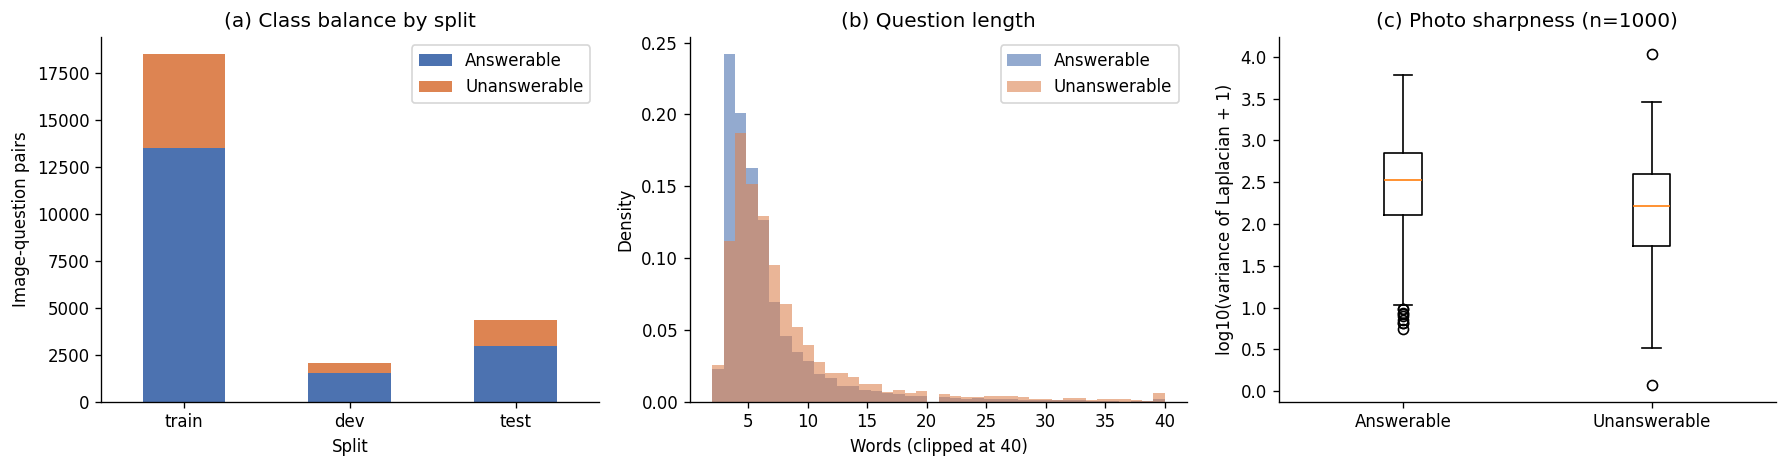

In [8]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
LABELS = {0: "Answerable", 1: "Unanswerable"}
COLOURS = {0: "#4C72B0", 1: "#DD8452"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

counts = meta.groupby(["split", "y"]).size().unstack().reindex(["train", "dev", "test"])
counts.columns = [LABELS[c] for c in counts.columns]
counts.plot(kind="bar", stacked=True, ax=axes[0], color=[COLOURS[0], COLOURS[1]], rot=0)
axes[0].set(title="(a) Class balance by split", xlabel="Split", ylabel="Image-question pairs")

for y in (0, 1):
    axes[1].hist(meta.loc[meta.y == y, "q_words"].clip(upper=40), bins=40, alpha=0.6,
                 density=True, label=LABELS[y], color=COLOURS[y])
axes[1].set(title="(b) Question length", xlabel="Words (clipped at 40)", ylabel="Density")
axes[1].legend()

axes[2].boxplot([np.log10(img_stats.loc[img_stats.y == y, "sharpness"] + 1) for y in (0, 1)])
axes[2].set_xticks([1, 2], [LABELS[0], LABELS[1]])
axes[2].set(title=f"(c) Photo sharpness (n={len(img_stats)})", ylabel="log10(variance of Laplacian + 1)")

fig.tight_layout()
fig.savefig(FIG_DIR / "pilot_eda.png", bbox_inches="tight")
plt.show()

## 5. Frozen feature extraction

Both encoders are frozen, loaded with Hugging Face Transformers (Wolf et al. 2020) and run once. Their outputs are cached to Drive, so every later model (here and in Project 2.2) trains on small arrays instead of raw photos. Freezing pretrained encoders suits a training set of about 20,000 pairs, which is too small to train image and text encoders from scratch.

- **Image:** ViT-B/16 pretrained on ImageNet-21k (Dosovitskiy et al. 2021). We keep the [CLS] vector, plus the 14x14 patch tokens average-pooled to 7x7 = 49 region tokens for cross-attention.
- **Text:** BERT-base, uncased (Devlin et al. 2019). We keep the [CLS] vector, a mask-aware mean, and the full token sequence for cross-attention.

Photos are resized to 224x224 without cropping, because questions often concern text near the edges of the frame. EXIF orientation is applied because phone photos are often stored rotated.

In [9]:
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoImageProcessor

FINGERPRINT = hashlib.md5("|".join(meta["image"]).encode()).hexdigest()[:12]  # ties cached features to this exact row order
FEATURE_NAMES = ["img_cls", "img_tok", "img_ok", "txt_cls", "txt_mean", "txt_tok", "txt_mask"]
feat_path = lambda name: FEAT_DIR / f"{name}_{FINGERPRINT}.npy"
EXTRACTION_LOG = FEAT_DIR / f"extraction_log_{FINGERPRINT}.json"


def autocast():
    return torch.autocast(device_type=DEVICE, dtype=torch.float16, enabled=(DEVICE == "cuda"))


class PhotoDataset(Dataset):
    def __init__(self, paths, size, mean, std):
        self.paths, self.size = list(paths), size
        self.mean = torch.tensor(mean, dtype=torch.float32).view(3, 1, 1)
        self.std = torch.tensor(std, dtype=torch.float32).view(3, 1, 1)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        try:
            with Image.open(self.paths[i]) as im:
                im.draft("RGB", (self.size, self.size))
                im = ImageOps.exif_transpose(im).convert("RGB").resize(
                    (self.size, self.size), Image.Resampling.BICUBIC)
            x = torch.from_numpy(np.asarray(im, dtype=np.float32) / 255.0).permute(2, 0, 1)
            return (x - self.mean) / self.std, 1
        except Exception:
            return torch.zeros(3, self.size, self.size), 0  # unreadable file: flagged, zero input


def peak_vram_gb():
    return round(torch.cuda.max_memory_allocated() / 1e9, 2) if DEVICE == "cuda" else None


# ViT-B/16 image encoder (Dosovitskiy et al. 2021), loaded with Hugging Face Transformers (Wolf et al. 2020)
@torch.no_grad()
def extract_image_features(paths):
    proc = AutoImageProcessor.from_pretrained(CONFIG["image_model"])
    model = AutoModel.from_pretrained(CONFIG["image_model"]).to(DEVICE).eval()
    ds = PhotoDataset(paths, CONFIG["image_size"], proc.image_mean, proc.image_std)
    dl = DataLoader(ds, batch_size=CONFIG["extract_batch_size"], num_workers=CONFIG["num_workers"],
                    pin_memory=(DEVICE == "cuda"))
    n, g, d = len(ds), CONFIG["image_token_grid"], model.config.hidden_size
    cls, tok, ok = np.empty((n, d), np.float16), np.empty((n, g * g, d), np.float16), np.empty(n, np.uint8)
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0, i = time.time(), 0
    for x, flag in tqdm(dl, desc="ViT features"):
        x = x.to(DEVICE, non_blocking=True)
        with autocast():
            h = model(pixel_values=x).last_hidden_state  # [B, 1 + P, D]
        b, side = len(x), int(round((h.shape[1] - 1) ** 0.5))
        grid = h[:, 1:].float().reshape(b, side, side, d).permute(0, 3, 1, 2)
        regions = F.adaptive_avg_pool2d(grid, g).flatten(2).transpose(1, 2)  # [B, g*g, D]
        cls[i:i + b], tok[i:i + b], ok[i:i + b] = h[:, 0].float().cpu().numpy(), regions.cpu().numpy(), flag.numpy()
        i += b
    secs = time.time() - t0
    FEAS["image_extraction"] = {"n": n, "minutes": round(secs / 60, 1), "images_per_sec": round(n / secs, 1),
                                "peak_vram_gb": peak_vram_gb(), "unreadable_images": int((ok == 0).sum())}
    del model
    return cls, tok, ok


# BERT-base text encoder (Devlin et al. 2019)
@torch.no_grad()
def extract_text_features(questions):
    model = AutoModel.from_pretrained(CONFIG["text_model"]).to(DEVICE).eval()
    n, L, d, bs = len(questions), CONFIG["max_q_tokens"], model.config.hidden_size, 2 * CONFIG["extract_batch_size"]
    cls, mean = np.empty((n, d), np.float16), np.empty((n, d), np.float16)
    tok, mask = np.empty((n, L, d), np.float16), np.empty((n, L), np.uint8)
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for i in tqdm(range(0, n, bs), desc="BERT features"):
        enc = tokenizer(questions[i:i + bs], padding="max_length", truncation=True,
                        max_length=L, return_tensors="pt").to(DEVICE)
        with autocast():
            h = model(**enc).last_hidden_state
        h, m = h.float(), enc["attention_mask"].unsqueeze(-1).float()
        cls[i:i + bs] = h[:, 0].cpu().numpy()
        mean[i:i + bs] = ((h * m).sum(1) / m.sum(1).clamp(min=1)).cpu().numpy()
        tok[i:i + bs], mask[i:i + bs] = h.cpu().numpy(), enc["attention_mask"].cpu().numpy()
    secs = time.time() - t0
    FEAS["text_extraction"] = {"n": n, "minutes": round(secs / 60, 1), "peak_vram_gb": peak_vram_gb()}
    del model
    return cls, mean, tok, mask


if all(feat_path(n).exists() for n in FEATURE_NAMES):
    FEATS = {n: np.load(feat_path(n)) for n in FEATURE_NAMES}
    if EXTRACTION_LOG.exists():
        FEAS.update(json.loads(EXTRACTION_LOG.read_text()))
    print(f"Loaded cached features ({FINGERPRINT})")
else:
    img_cls, img_tok, img_ok = extract_image_features(meta["path"].tolist())
    txt_cls, txt_mean, txt_tok, txt_mask = extract_text_features(meta["question"].tolist())
    FEATS = dict(img_cls=img_cls, img_tok=img_tok, img_ok=img_ok, txt_cls=txt_cls,
                 txt_mean=txt_mean, txt_tok=txt_tok, txt_mask=txt_mask)
    for n, arr in FEATS.items():
        np.save(feat_path(n), arr)
    meta.drop(columns=["answers", "path"]).to_csv(FEAT_DIR / f"meta_{FINGERPRINT}.csv", index=False)
    EXTRACTION_LOG.write_text(json.dumps({k: FEAS[k] for k in ("image_extraction", "text_extraction")}, indent=2))
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

FEAS["features_on_disk_gb"] = round(sum(feat_path(n).stat().st_size for n in FEATURE_NAMES) / 1e9, 2)
print(json.dumps({k: FEAS.get(k) for k in ("image_extraction", "text_extraction", "features_on_disk_gb")}, indent=2))

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/502 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

...

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


BERT features:   0%|          | 0/195 [00:00<?, ?it/s]

{
  "image_extraction": {
    "n": 24842,
    "minutes": 4.9,
    "images_per_sec": 85.3,
    "peak_vram_gb": 0.94,
    "unreadable_images": 0
  },
  "text_extraction": {
    "n": 24842,
    "minutes": 0.3,
    "peak_vram_gb": 0.78
  },
  "features_on_disk_gb": 3.51
}


## 6. Pilot models

Five pilot models, written in PyTorch (Paszke et al. 2019), share the same loss, optimiser, early stopping and threshold rule, so differences come only from the inputs and the fusion strategy. The fusion levels follow the early, late and intermediate taxonomy of Baltrusaitis, Ahuja & Morency (2019):

- **Question-only** and **Image-only** MLPs: how far each modality gets alone.
- **Early fusion:** concatenated question and image vectors, then an MLP.
- **Late fusion:** weighted average of the two unimodal probabilities, with the weight tuned on dev.
- **Cross-attention:** one bidirectional block of scaled dot-product attention (Vaswani et al. 2017) in which question tokens attend to image regions and image regions attend to question tokens, following the crossmodal attention of Tsai et al. (2019); the result is pooled, then passed to an MLP.

Class imbalance is handled with `pos_weight` in the loss, and every model is trained with AdamW (Loshchilov & Hutter 2019). Each model is selected on dev AUPRC, which is more informative than ROC analysis when classes are imbalanced (Saito & Rehmsmeier 2015); its decision threshold is tuned on dev for macro-F1, and the final numbers come from the held-out test split. Metrics come from scikit-learn (Pedregosa et al. 2011), and 95% confidence intervals use a paired percentile bootstrap (Efron & Tibshirani 1993).

In [10]:
# Models in PyTorch (Paszke et al. 2019); metrics from scikit-learn (Pedregosa et al. 2011)
import torch.nn as nn
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             f1_score, roc_auc_score)

T = {k: torch.from_numpy(v) for k, v in FEATS.items()}  # CPU float16; batches move to the GPU on demand
X_Q, X_I = T["txt_mean"], T["img_cls"]
X_QI = torch.cat([X_Q, X_I], 1)
Y_T = torch.from_numpy(Y)


class MLPHead(nn.Module):
    def __init__(self, d_in, d_hidden=256, p=0.3):
        super().__init__()
        self.net = nn.Sequential(nn.LayerNorm(d_in), nn.Linear(d_in, d_hidden), nn.GELU(),
                                 nn.Dropout(p), nn.Linear(d_hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


# Scaled dot-product attention (Vaswani et al. 2017) applied across modalities, as in Tsai et al. (2019)
class CrossAttentionFusion(nn.Module):
    """One bidirectional cross-attention block over question tokens and image region tokens."""

    def __init__(self, d_in, d_model=256, heads=4, p=0.1):
        super().__init__()
        self.q_proj, self.v_proj = nn.Linear(d_in, d_model), nn.Linear(d_in, d_model)
        self.q_from_v = nn.MultiheadAttention(d_model, heads, dropout=p, batch_first=True)
        self.v_from_q = nn.MultiheadAttention(d_model, heads, dropout=p, batch_first=True)
        self.ln_q, self.ln_v = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.head = MLPHead(2 * d_model, 128)

    def forward(self, q_tok, q_mask, v_tok):
        q, v = self.q_proj(q_tok), self.v_proj(v_tok)
        q = self.ln_q(q + self.q_from_v(q, v, v)[0])                            # question attends to image
        v = self.ln_v(v + self.v_from_q(v, q, q, key_padding_mask=~q_mask)[0])  # image attends to question
        m = q_mask.unsqueeze(-1).float()
        q_pool = (q * m).sum(1) / m.sum(1).clamp(min=1)
        return self.head(torch.cat([q_pool, v.mean(1)], -1))


def vector_batch(X):
    return lambda idx: (X[torch.as_tensor(idx)].to(DEVICE).float(),)


def token_batch(idx):
    idx = torch.as_tensor(idx)
    return (T["txt_tok"][idx].to(DEVICE).float(), T["txt_mask"][idx].to(DEVICE).bool(),
            T["img_tok"][idx].to(DEVICE).float())


@torch.no_grad()
def predict(model, get_batch, idx, bs=1024):
    model.eval()
    out = [torch.sigmoid(model(*get_batch(idx[i:i + bs]))).float().cpu() for i in range(0, len(idx), bs)]
    return torch.cat(out).numpy()


def log_loss(p, y, eps=1e-7):
    p = np.clip(p, eps, 1 - eps)
    return float(-(y * np.log(p) + (1 - y) * np.log(1 - p)).mean())


def train(model, get_batch, cfg=CONFIG):
    """Train with early stopping on dev AUPRC; log train/dev loss each epoch to assess overfitting."""
    model = model.to(DEVICE)
    tr, dev = IDX["train"], IDX["dev"]
    pos = float(Y[tr].mean())
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1 - pos) / pos, dtype=torch.float32, device=DEVICE))
    # AdamW: Adam with decoupled weight decay (Loshchilov & Hutter 2019)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    rng = np.random.default_rng(cfg["seed"])
    tr_probe = rng.choice(tr, size=min(len(tr), 5000), replace=False)  # eval-mode train loss on a fixed subset
    hist, best_ap, best_state, bad, epoch_secs = [], -1.0, None, 0, []
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for ep in range(cfg["epochs"]):
        model.train()
        t0 = time.time()
        for b in np.array_split(rng.permutation(tr), max(1, len(tr) // cfg["train_batch_size"])):
            loss = loss_fn(model(*get_batch(b)), Y_T[torch.as_tensor(b)].to(DEVICE))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        epoch_secs.append(time.time() - t0)
        p_tr, p_dev = predict(model, get_batch, tr_probe), predict(model, get_batch, dev)
        # Select on AUPRC, which suits imbalanced classes better than ROC (Saito & Rehmsmeier 2015)
        ap = average_precision_score(Y[dev], p_dev)
        hist.append({"epoch": ep + 1, "train_loss": log_loss(p_tr, Y[tr_probe]),
                     "dev_loss": log_loss(p_dev, Y[dev]), "dev_auprc": ap})
        if ap > best_ap:
            best_ap, best_state, bad = ap, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= cfg["patience"]:
                break
    model.load_state_dict(best_state)
    cost = {"sec_per_epoch": round(float(np.mean(epoch_secs)), 2), "epochs_run": len(hist),
            "params": int(sum(p.numel() for p in model.parameters())), "peak_vram_gb": peak_vram_gb()}
    return model, pd.DataFrame(hist), cost


def tune_threshold(p, y):
    grid = np.linspace(0.05, 0.95, 91)
    return float(grid[int(np.argmax([f1_score(y, p >= t, average="macro") for t in grid]))])


def evaluate(p, y, t):
    yhat = (p >= t).astype(int)
    return {"macro_f1": f1_score(y, yhat, average="macro"), "f1_unanswerable": f1_score(y, yhat),
            "balanced_acc": balanced_accuracy_score(y, yhat), "accuracy": accuracy_score(y, yhat),
            "auroc": roc_auc_score(y, p), "auprc": average_precision_score(y, p)}

In [11]:
# Early, late and intermediate fusion levels follow Baltrusaitis, Ahuja & Morency (2019)
SPECS = {
    "Question-only": (lambda: MLPHead(X_Q.shape[1]), vector_batch(X_Q)),
    "Image-only": (lambda: MLPHead(X_I.shape[1]), vector_batch(X_I)),
    "Early fusion": (lambda: MLPHead(X_QI.shape[1]), vector_batch(X_QI)),
    "Cross-attention": (lambda: CrossAttentionFusion(T["txt_tok"].shape[2]), token_batch),
}
PRED, HIST, COST, THR = {}, {}, {}, {}
y_dev = Y[IDX["dev"]]

for name, (make, get_batch) in SPECS.items():
    set_seed(CONFIG["seed"])
    model, HIST[name], COST[name] = train(make(), get_batch)
    PRED[name] = {s: predict(model, get_batch, IDX[s]) for s in ("dev", "test")}
    THR[name] = tune_threshold(PRED[name]["dev"], y_dev)
    print(f"{name:16s} {COST[name]['epochs_run']:2d} epochs, {COST[name]['sec_per_epoch']:5.1f} s/epoch, "
          f"best dev AUPRC {HIST[name].dev_auprc.max():.3f}")

# Late fusion: weighted average of the unimodal probabilities, weight chosen on dev AUPRC
weights = np.linspace(0, 1, 21)
w_q = float(weights[np.argmax([average_precision_score(
    y_dev, w * PRED["Question-only"]["dev"] + (1 - w) * PRED["Image-only"]["dev"]) for w in weights])])
PRED["Late fusion"] = {s: w_q * PRED["Question-only"][s] + (1 - w_q) * PRED["Image-only"][s] for s in ("dev", "test")}
THR["Late fusion"] = tune_threshold(PRED["Late fusion"]["dev"], y_dev)
COST["Late fusion"] = {"sec_per_epoch": 0.0, "epochs_run": 0, "params": 0, "peak_vram_gb": None}
print(f"Late fusion question weight (tuned on dev): {w_q:.2f}")

Question-only     6 epochs,   0.3 s/epoch, best dev AUPRC 0.514
Image-only        5 epochs,   0.2 s/epoch, best dev AUPRC 0.590
Early fusion      7 epochs,   0.2 s/epoch, best dev AUPRC 0.726
Cross-attention   6 epochs,   3.9 s/epoch, best dev AUPRC 0.712
Late fusion question weight (tuned on dev): 0.45


In [12]:
ORDER = ["Question-only", "Image-only", "Early fusion", "Late fusion", "Cross-attention"]
y_test = Y[IDX["test"]].astype(int)
# Paired percentile bootstrap confidence intervals (Efron & Tibshirani 1993)
rng = np.random.default_rng(CONFIG["seed"])
BOOT_IDX = [rng.integers(0, len(y_test), len(y_test)) for _ in range(CONFIG["n_bootstrap"])]


def bootstrap_macro_f1(name):
    yhat = (PRED[name]["test"] >= THR[name]).astype(int)
    return np.array([f1_score(y_test[b], yhat[b], average="macro") for b in BOOT_IDX])


BOOT = {n: bootstrap_macro_f1(n) for n in tqdm(ORDER, desc="bootstrap")}
rows = []
for n in ORDER:
    lo, hi = np.percentile(BOOT[n], [2.5, 97.5])
    rows.append({"model": n, **{k: round(float(v), 3) for k, v in evaluate(PRED[n]["test"], y_test, THR[n]).items()},
                 "macro_f1_ci95": f"[{lo:.3f}, {hi:.3f}]", "threshold": round(THR[n], 2), **COST[n]})
results = pd.DataFrame(rows).set_index("model")
results.to_csv(RES_DIR / "pilot_results.csv")
display(results)

# Paired bootstrap: is the best fusion model better than the best single-modality model?
best_uni = max(["Question-only", "Image-only"], key=lambda n: results.loc[n, "macro_f1"])
best_fus = max(["Early fusion", "Late fusion", "Cross-attention"], key=lambda n: results.loc[n, "macro_f1"])
GAIN = {"best_unimodal": best_uni, "best_fusion": best_fus,
        "macro_f1_gain": round(float(results.loc[best_fus, "macro_f1"] - results.loc[best_uni, "macro_f1"]), 3),
        "gain_ci95": [round(float(x), 3) for x in np.percentile(BOOT[best_fus] - BOOT[best_uni], [2.5, 97.5])]}

# Complementarity: how often does only one modality get a test pair right?
correct = {n: (PRED[n]["test"] >= THR[n]).astype(int) == y_test for n in ("Question-only", "Image-only")}
q_ok, i_ok = correct["Question-only"], correct["Image-only"]
COMPLEMENT = {k: round(float(v), 3) for k, v in {
    "both_correct": (q_ok & i_ok).mean(), "only_question_correct": (q_ok & ~i_ok).mean(),
    "only_image_correct": (~q_ok & i_ok).mean(), "both_wrong": (~q_ok & ~i_ok).mean(),
    "oracle_accuracy": (q_ok | i_ok).mean()}.items()}
print(json.dumps({"fusion_gain": GAIN, "complementarity": COMPLEMENT}, indent=2))

bootstrap:   0%|          | 0/5 [00:00<?, ?it/s]

,macro_f1,f1_unanswerable,balanced_acc,accuracy,auroc,auprc,macro_f1_ci95,threshold,sec_per_epoch,epochs_run,params,peak_vram_gb
model,,,,,,,,,,,,
Question-only,0.650,0.534,0.654,0.689,0.732,0.565,"[0.635, 0.666]",0.55,0.30,6,198657,0.03
Image-only,0.688,0.588,0.695,0.719,0.763,0.613,"[0.673, 0.701]",0.55,0.21,5,198657,0.03
Early fusion,0.756,0.668,0.756,0.787,0.851,0.732,"[0.742, 0.770]",0.58,0.24,7,396801,0.04
Late fusion,0.727,0.647,0.741,0.750,0.825,0.696,"[0.714, 0.741]",0.52,0.00,0,0,NaN
Cross-attention,0.758,0.680,0.766,0.784,0.855,0.737,"[0.744, 0.772]",0.57,3.92,6,987905,0.74


{
  "fusion_gain": {
    "best_unimodal": "Image-only",
    "best_fusion": "Cross-attention",
    "macro_f1_gain": 0.07,
    "gain_ci95": [
      0.055,
      0.087
    ]
  },
  "complementarity": {
    "both_correct": 0.506,
    "only_question_correct": 0.183,
    "only_image_correct": 0.213,
    "both_wrong": 0.098,
    "oracle_accuracy": 0.902
  }
}


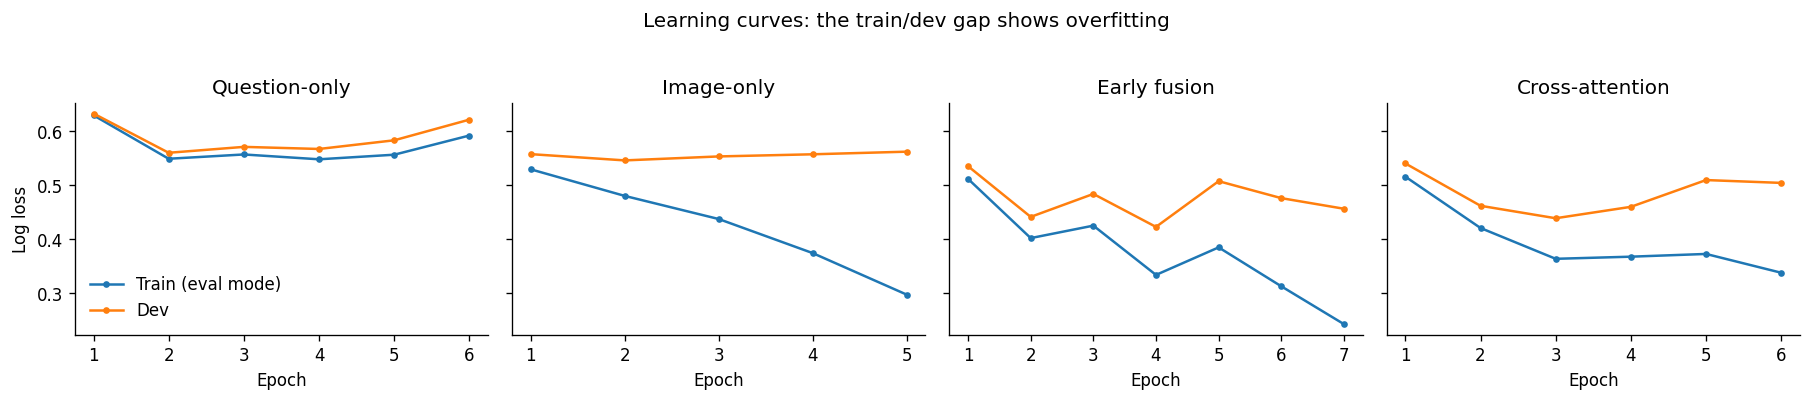

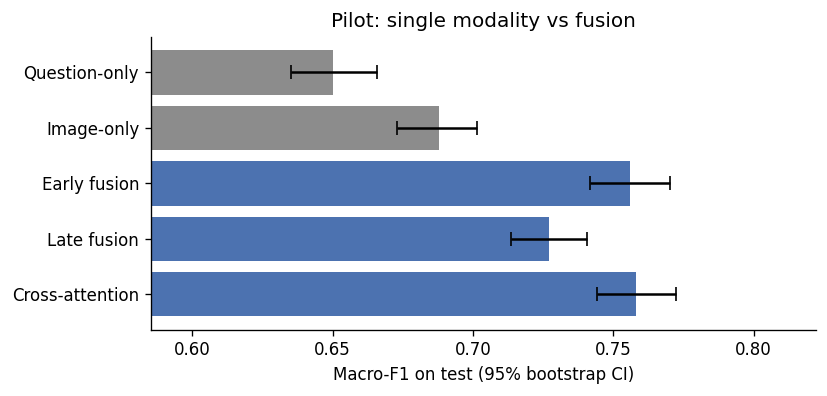

In [13]:
trained = [n for n in ORDER if n in HIST]
fig, axes = plt.subplots(1, len(trained), figsize=(3.8 * len(trained), 3.2), sharey=True)
for ax, n in zip(axes, trained):
    ax.plot(HIST[n].epoch, HIST[n].train_loss, marker="o", ms=3, label="Train (eval mode)")
    ax.plot(HIST[n].epoch, HIST[n].dev_loss, marker="o", ms=3, label="Dev")
    ax.set(title=n, xlabel="Epoch")
axes[0].set_ylabel("Log loss")
axes[0].legend(frameon=False)
fig.suptitle("Learning curves: the train/dev gap shows overfitting", y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "pilot_learning_curves.png", bbox_inches="tight")
plt.show()

f1 = results.loc[ORDER, "macro_f1"].values
ci = np.array([np.percentile(BOOT[n], [2.5, 97.5]) for n in ORDER])
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(ORDER, f1, xerr=[np.clip(f1 - ci[:, 0], 0, None), np.clip(ci[:, 1] - f1, 0, None)], capsize=4,
        color=["#8C8C8C", "#8C8C8C", "#4C72B0", "#4C72B0", "#4C72B0"])
ax.invert_yaxis()
ax.set(xlabel="Macro-F1 on test (95% bootstrap CI)", title="Pilot: single modality vs fusion",
       xlim=(max(0, ci.min() - 0.05), min(1, ci.max() + 0.05)))
fig.tight_layout()
fig.savefig(FIG_DIR / "pilot_model_comparison.png", bbox_inches="tight")
plt.show()

## 7. Feasibility and proposal summary

The Project 2.2 compute estimate assumes every pilot model is run with 3 seeds x 4 configurations, plus one extra encoder pass for a CLIP reference baseline (Radford et al. 2021). Treat it as an order-of-magnitude figure.

Limitations of this pilot: a single seed, frozen encoders and no hyperparameter search. The results show feasibility and the size of the signal, not final performance.

In [14]:
def to_py(o):
    return o.item() if hasattr(o, "item") else str(o)


if DOWNLOAD_LOG.exists():
    FEAS["downloads"] = json.loads(DOWNLOAD_LOG.read_text())
train_min = sum(c["sec_per_epoch"] * c["epochs_run"] for c in COST.values()) / 60
extract_min = FEAS.get("image_extraction", {}).get("minutes", 0) + FEAS.get("text_extraction", {}).get("minutes", 0)
FEAS["pilot_training_minutes"] = round(train_min, 1)
FEAS["est_project_gpu_hours"] = round((train_min * 3 * 4 + extract_min + FEAS.get("image_extraction", {}).get("minutes", 0)) / 60, 1)
FEAS["peak_vram_gb_training"] = max((c["peak_vram_gb"] or 0) for c in COST.values())

SUMMARY = {"config": CONFIG, "data": STATS, "results_test": results.reset_index().to_dict(orient="records"),
           "fusion_gain": GAIN, "complementarity": COMPLEMENT, "feasibility": FEAS}
(RES_DIR / "pilot_summary.json").write_text(json.dumps(SUMMARY, indent=2, default=to_py))

ie = FEAS.get("image_extraction", {})
sharp = STATS["sharpness_median_by_label"]
print("=== Numbers for the proposal ===")
print(f"Data: {STATS['n_pairs']:,} image-question pairs (train {len(IDX['train']):,} / dev {len(IDX['dev']):,} / "
      f"test {len(IDX['test']):,}); {STATS['unanswerable_rate']:.1%} unanswerable.")
print(f"Questions: median {STATS['question_words_median']:.0f} words; {STATS['duplicate_questions_share']:.1%} of pairs "
      f"repeat another pair's exact question; {STATS['truncated_at_max_q_tokens']:.1%} truncated at {CONFIG['max_q_tokens']} tokens.")
print(f"Photos: median {STATS['image_megapixels_median']} MP; median sharpness answerable {sharp.get(0)} vs "
      f"unanswerable {sharp.get(1)} (Mann-Whitney p = {STATS['sharpness_mannwhitney_p']:.1e}).")
print(f"Label ambiguity: {STATS['ambiguous_answerable_share']:.1%} of pairs labelled answerable although "
      f">=3 of 10 workers said unanswerable.")
print(f"Complementarity: {COMPLEMENT['only_question_correct']:.1%} of test pairs solved only by the question model, "
      f"{COMPLEMENT['only_image_correct']:.1%} only by the image model (oracle accuracy {COMPLEMENT['oracle_accuracy']:.1%}).")
print(f"Fusion gain: {GAIN['best_fusion']} vs {GAIN['best_unimodal']}: macro-F1 {GAIN['macro_f1_gain']:+.3f} "
      f"(95% CI {GAIN['gain_ci95']}).")
print(f"Compute: {FEAS.get('gpu', 'CPU')}; image features {ie.get('images_per_sec')} img/s ({ie.get('minutes')} min, "
      f"peak {ie.get('peak_vram_gb')} GB VRAM); pilot training {FEAS['pilot_training_minutes']} min "
      f"(peak {FEAS['peak_vram_gb_training']} GB); features {FEAS['features_on_disk_gb']} GB; "
      f"estimated Project 2.2 budget ~{FEAS['est_project_gpu_hours']} GPU-hours.")
print(f"\nSaved: {RES_DIR / 'pilot_summary.json'}, {RES_DIR / 'pilot_results.csv'}, figures in {FIG_DIR}")

=== Numbers for the proposal ===
Data: 24,842 image-question pairs (train 18,470 / dev 2,053 / test 4,319); 27.8% unanswerable.
Questions: median 5 words; 57.6% of pairs repeat another pair's exact question; 0.9% truncated at 40 tokens.
Photos: median 2.0 MP; median sharpness answerable 338.7 vs unanswerable 163.7 (Mann-Whitney p = 1.8e-11).
Label ambiguity: 12.3% of pairs labelled answerable although >=3 of 10 workers said unanswerable.
Complementarity: 18.3% of test pairs solved only by the question model, 21.3% only by the image model (oracle accuracy 90.2%).
Fusion gain: Cross-attention vs Image-only: macro-F1 +0.070 (95% CI [0.055, 0.087]).
Compute: Tesla T4; image features 85.3 img/s (4.9 min, peak 0.94 GB VRAM); pilot training 0.5 min (peak 0.74 GB); features 3.51 GB; estimated Project 2.2 budget ~0.3 GPU-hours.

Saved: /content/drive/MyDrive/vizwiz_fusion/results/pilot_summary.json, /content/drive/MyDrive/vizwiz_fusion/results/pilot_results.csv, figures in /content/drive/MyDriv

## References

Baltrusaitis, T, Ahuja, C & Morency, L-P 2019, 'Multimodal machine learning: a survey and taxonomy', *IEEE Transactions on Pattern Analysis and Machine Intelligence*, vol. 41, no. 2, pp. 423-443.

Devlin, J, Chang, M-W, Lee, K & Toutanova, K 2019, 'BERT: pre-training of deep bidirectional transformers for language understanding', in *Proceedings of the 2019 conference of the North American chapter of the Association for Computational Linguistics: human language technologies*, vol. 1, Association for Computational Linguistics, Minneapolis, USA, pp. 4171-4186.

Dosovitskiy, A, Beyer, L, Kolesnikov, A, Weissenborn, D, Zhai, X, Unterthiner, T, Dehghani, M, Minderer, M, Heigold, G, Gelly, S, Uszkoreit, J & Houlsby, N 2021, 'An image is worth 16x16 words: transformers for image recognition at scale', in *International conference on learning representations (ICLR 2021)*, online.

Efron, B & Tibshirani, RJ 1993, *An introduction to the bootstrap*, Chapman & Hall, New York.

Gurari, D, Li, Q, Stangl, AJ, Guo, A, Lin, C, Grauman, K, Luo, J & Bigham, JP 2018, 'VizWiz grand challenge: answering visual questions from blind people', in *Proceedings of the IEEE conference on computer vision and pattern recognition (CVPR)*, IEEE, Salt Lake City, USA, pp. 3608-3617.

Loshchilov, I & Hutter, F 2019, 'Decoupled weight decay regularization', in *International conference on learning representations (ICLR 2019)*, New Orleans, USA.

Mann, HB & Whitney, DR 1947, 'On a test of whether one of two random variables is stochastically larger than the other', *Annals of Mathematical Statistics*, vol. 18, no. 1, pp. 50-60.

Paszke, A, Gross, S, Massa, F, Lerer, A, Bradbury, J, Chanan, G, Killeen, T, Lin, Z, Gimelshein, N, Antiga, L, Desmaison, A, Kopf, A, Yang, E, DeVito, Z, Raison, M, Tejani, A, Chilamkurthy, S, Steiner, B, Fang, L, Bai, J & Chintala, S 2019, 'PyTorch: an imperative style, high-performance deep learning library', in *Advances in neural information processing systems 32 (NeurIPS 2019)*, Curran Associates, Vancouver, Canada, pp. 8024-8035.

Pech-Pacheco, JL, Cristobal, G, Chamorro-Martinez, J & Fernandez-Valdivia, J 2000, 'Diatom autofocusing in brightfield microscopy: a comparative study', in *Proceedings of the 15th international conference on pattern recognition (ICPR 2000)*, vol. 3, IEEE, Barcelona, Spain, pp. 314-317.

Pedregosa, F, Varoquaux, G, Gramfort, A, Michel, V, Thirion, B, Grisel, O, Blondel, M, Prettenhofer, P, Weiss, R, Dubourg, V, Vanderplas, J, Passos, A, Cournapeau, D, Brucher, M, Perrot, M & Duchesnay, E 2011, 'Scikit-learn: machine learning in Python', *Journal of Machine Learning Research*, vol. 12, pp. 2825-2830.

Radford, A, Kim, JW, Hallacy, C, Ramesh, A, Goh, G, Agarwal, S, Sastry, G, Askell, A, Mishkin, P, Clark, J, Krueger, G & Sutskever, I 2021, 'Learning transferable visual models from natural language supervision', in *Proceedings of the 38th international conference on machine learning (ICML 2021)*, PMLR, vol. 139, pp. 8748-8763.

Saito, T & Rehmsmeier, M 2015, 'The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets', *PLoS ONE*, vol. 10, no. 3, article no. e0118432.

Tsai, Y-HH, Bai, S, Liang, PP, Kolter, JZ, Morency, L-P & Salakhutdinov, R 2019, 'Multimodal transformer for unaligned multimodal language sequences', in *Proceedings of the 57th annual meeting of the Association for Computational Linguistics*, Association for Computational Linguistics, Florence, Italy, pp. 6558-6569.

Vaswani, A, Shazeer, N, Parmar, N, Uszkoreit, J, Jones, L, Gomez, AN, Kaiser, L & Polosukhin, I 2017, 'Attention is all you need', in *Advances in neural information processing systems 30 (NIPS 2017)*, Curran Associates, Long Beach, USA, pp. 5998-6008.

VizWiz n.d., *Visual question answering*, VizWiz, viewed 20 October 2026, <https://vizwiz.org/tasks-and-datasets/vqa/>.

Wolf, T, Debut, L, Sanh, V, Chaumond, J, Delangue, C, Moi, A, Cistac, P, Rault, T, Louf, R, Funtowicz, M, Davison, J, Shleifer, S, von Platen, P, Ma, C, Jernite, Y, Plu, J, Xu, C, Le Scao, T, Gugger, S, Drame, M, Lhoest, Q & Rush, AM 2020, 'Transformers: state-of-the-art natural language processing', in *Proceedings of the 2020 conference on empirical methods in natural language processing: system demonstrations*, Association for Computational Linguistics, online, pp. 38-45.